# The EDA workflow and initial exploration — Code-Along Template

**Type into this notebook during class.** The explanation is here; the code is not.

| | |
|---|---|
| **Follow along** | Write the code in each `# TODO` cell. The hint names the functions and arguments. |
| **If you fall behind** | Do not copy frantically. Skip to the next **CHECKPOINT**, run it, rejoin. |
| **If a cell errors** | Later cells depend on it and will fail too. Run the next CHECKPOINT rather than debugging under time pressure. |
| **After class** | The worked version is `D004_01d_EDA_Workflow.ipynb`. Compare, do not copy. |

Cells that are already filled in are deliberate — imports and quick glances at the
data cost class time and teach nothing.

# Module 01d: EDA Workflow & Chart Selection Guide

## Learning Objectives

By the end of this notebook, you will be able to:
- Follow a structured EDA (Exploratory Data Analysis) workflow
- Choose the right chart type for any data scenario
- Interpret common visualization patterns correctly
- Apply best practices for data storytelling
- Avoid common visualization mistakes

**This notebook is a reference guide you'll use throughout your data science journey!**

---

## 1. The EDA Process

**EDA (Exploratory Data Analysis)** is the detective work of data science.

### The 5-Step EDA Workflow

```
┌─────────────┐     ┌─────────────┐     ┌─────────────┐     ┌─────────────┐     ┌─────────────┐
│   1. LOAD   │ ──► │  2. INSPECT │ ──► │  3. CLEAN   │ ──► │ 4. EXPLORE  │ ──► │ 5. SUMMARIZE│
│   the data  │     │   the data  │     │   the data  │     │  visually   │     │   findings  │
└─────────────┘     └─────────────┘     └─────────────┘     └─────────────┘     └─────────────┘
```

### Step 1: LOAD
- Read data from file (CSV, Excel, JSON, SQL)
- Check if loading was successful

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# Load sample data
df = sns.load_dataset('tips')
print(f"Data loaded: {df.shape[0]} rows, {df.shape[1]} columns")

Data loaded: 244 rows, 7 columns


In [ ]:
# ═══ CHECKPOINT — "Step 2: INSPECT" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['figure.figsize'] = (10, 6)
df = sns.load_dataset('tips')

print("Checkpoint restored. Ready for: Step 2: INSPECT")

### Step 2: INSPECT
- What columns do we have?
- What are the data types?
- Are there missing values?

In [2]:
# Quick inspection checklist
print("="*50)
print("STEP 2: DATA INSPECTION")
print("="*50)

print("\n1. First few rows:")
display(df.head())

print("\n2. Data types:")
print(df.dtypes)

print("\n3. Missing values:")
print(df.isnull().sum())

print("\n4. Basic statistics:")
display(df.describe())

STEP 2: DATA INSPECTION

1. First few rows:


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4



2. Data types:
total_bill     float64
tip            float64
sex           category
smoker        category
day           category
time          category
size             int64
dtype: object

3. Missing values:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

4. Basic statistics:


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


### Step 3: CLEAN
- Handle missing values
- Fix data types if needed
- Remove duplicates

In [3]:
# Cleaning checklist (already clean in this case)
print("="*50)
print("STEP 3: DATA CLEANING")
print("="*50)

print(f"\nDuplicates: {df.duplicated().sum()}")
print(f"Missing values total: {df.isnull().sum().sum()}")
print("\nData is clean! Ready for exploration.")

STEP 3: DATA CLEANING

Duplicates: 1
Missing values total: 0

Data is clean! Ready for exploration.


### Step 4: EXPLORE (This is where visualization comes in!)

We'll cover this in detail below with the Chart Selection Guide.

### Step 5: SUMMARIZE
- Write key findings
- Note any data quality issues
- List next steps

---

## 2. Chart Selection Decision Tree

**The #1 question to ask: "What am I trying to show?"**

### Quick Reference Table

| Your Data | Your Question | Best Chart | Code |
|-----------|---------------|------------|------|
| 1 numeric | Distribution? | Histogram | `sns.histplot()` |
| 1 numeric | Distribution + shape? | Histogram + KDE | `sns.histplot(kde=True)` |
| 1 numeric by category | Compare distributions? | Box plot | `sns.boxplot()` |
| 1 numeric by category | Full distribution shape? | Violin plot | `sns.violinplot()` |
| 2 numeric | Relationship? | Scatter plot | `sns.scatterplot()` |
| 2 numeric | Relationship + trend? | Regression plot | `sns.regplot()` |
| Time + numeric | Trend over time? | Line plot | `plt.plot()` / `sns.lineplot()` |
| 1 categorical | Counts? | Bar chart | `sns.countplot()` |
| 1 cat + 1 numeric | Compare means? | Bar chart | `sns.barplot()` |
| Many numeric | All correlations? | Heatmap | `sns.heatmap()` |
| Many numeric | All relationships? | Pair plot | `sns.pairplot()` |
| Parts of whole | Composition? | Stacked bar (or pie) | `plt.bar(bottom=...)` |

### Flowchart: Choosing Your Chart

```
START: How many variables are you visualizing?
│
├── ONE VARIABLE
│   ├── Numeric? ──► Histogram or Box plot
│   └── Categorical? ──► Bar chart (counts)
│
├── TWO VARIABLES
│   ├── Both numeric? ──► Scatter plot
│   ├── One numeric, one categorical? ──► Box plot or Bar chart
│   ├── Both categorical? ──► Heatmap (crosstab counts)
│   └── Time + numeric? ──► Line chart
│
└── THREE+ VARIABLES
    ├── Add color (hue) to any of the above
    ├── Use size for another dimension
    ├── Use facet grid for categories
    └── Use pair plot for many numeric
```

---

## 3. Visual Examples of Each Chart Type

Let's see each chart type in action with the Tips dataset.

### 3.1 One Numeric Variable: Distribution

In [ ]:
# TODO: draw a histogram of `total_bill`
# Hint: plt.subplots, sns.histplot, .set_title(), sns.boxplot, plt.suptitle

### 3.2 One Numeric + One Categorical: Compare Groups

In [ ]:
# TODO: draw a boxplot of `day`
# Hint: plt.subplots, sns.boxplot, .set_title(), sns.violinplot, sns.barplot

In [ ]:
# ═══ CHECKPOINT — "Two Numeric Variables: Relationships" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['figure.figsize'] = (10, 6)
df = sns.load_dataset('tips')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

print("Checkpoint restored. Ready for: Two Numeric Variables: Relationships")

### 3.3 Two Numeric Variables: Relationships

In [ ]:
# TODO: draw a scatter plot of `total_bill`, split by `time`
# Hint: plt.subplots, sns.scatterplot, .set_title(), sns.regplot, plt.suptitle

### 3.4 Many Variables: Overview

In [ ]:
# TODO: draw a `plt.subplots`
# Hint: plt.subplots, .corr(), sns.heatmap, ax.set_title, plt.show
# Name your result: corr

In [ ]:
# TODO: draw a `sns.pairplot`
# Hint: sns.pairplot, plt.suptitle, plt.show

---

## 4. Interpretation Cheat Sheet

### 4.1 Histogram/Distribution Patterns

| Shape | What It Looks Like | What It Means | Action |
|-------|-------------------|---------------|--------|
| **Normal (Bell)** | Symmetric, one peak | Most values near mean | Parametric tests OK |
| **Right-skewed** | Long tail to right | Few high outliers | Consider log transform |
| **Left-skewed** | Long tail to left | Few low outliers | Consider transform |
| **Bimodal** | Two peaks | Two distinct groups | Investigate subgroups |
| **Uniform** | Flat, no peaks | All values equally likely | Check if expected |

In [ ]:
# TODO: draw a `plt.subplots`
# Hint: plt.subplots, np.random.seed, .hist(), .set_title(), np.concatenate
# Name your result: bimodal

In [ ]:
# ═══ CHECKPOINT — "Scatter Plot Patterns" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['figure.figsize'] = (10, 6)
df = sns.load_dataset('tips')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig, ax = plt.subplots(figsize=(8, 6))
corr = df.select_dtypes(include=[np.number]).corr()
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
bimodal = np.concatenate([np.random.normal(-2, 0.5, 500), np.random.normal(2, 0.5, 500)])

print("Checkpoint restored. Ready for: Scatter Plot Patterns")

### 4.2 Scatter Plot Patterns

| Pattern | What It Means | Correlation | Example |
|---------|---------------|-------------|----------|
| **Upward diagonal** | Positive correlation | +0.5 to +1.0 | Height vs Weight |
| **Downward diagonal** | Negative correlation | -0.5 to -1.0 | Price vs Demand |
| **Cloud (no pattern)** | No linear relationship | -0.3 to +0.3 | Shoe size vs IQ |
| **Curved** | Non-linear relationship | Varies | Age vs Reaction time |
| **Clusters** | Distinct groups | N/A | Customer segments |

In [ ]:
# TODO: draw a `plt.subplots`
# Hint: plt.subplots, np.random.seed, np.random.randn, .scatter(), .set_title()
# Name your result: n, x, x_clusters, y_clusters

### 4.3 Box Plot Elements

```
          ┌──────────────────────────────────────────────────────┐
          │                      UPPER WHISKER                    │
          │                           │                           │
          │  ─────────────────────────┼───────────────────────── │
          │  │                        │                        │ │
          │  │         Q3 (75th)  ────┼───────────────────────── │
          │  │                        │                        │ │
          │  │                    ────┼──── MEDIAN (50th)      │ │
          │  │                        │                        │ │
          │  │         Q1 (25th)  ────┼───────────────────────── │
          │  │                        │                        │ │
          │  ─────────────────────────┼───────────────────────── │
          │                           │                           │
          │                      LOWER WHISKER                    │
          │                                                       │
          │    ●    ●                        OUTLIERS             │
          └──────────────────────────────────────────────────────┘
```

| Element | What It Shows |
|---------|---------------|
| **Box** | Middle 50% of data (IQR) |
| **Line in box** | Median (50th percentile) |
| **Whiskers** | Extend to 1.5 × IQR |
| **Dots** | Outliers beyond whiskers |

### 4.4 Correlation Heatmap Values

| Value | Strength | Color (coolwarm) | Interpretation |
|-------|----------|------------------|----------------|
| +0.7 to +1.0 | Strong positive | Dark red | Variables increase together |
| +0.4 to +0.7 | Moderate positive | Light red | Somewhat related |
| -0.3 to +0.3 | Weak/None | White/Light | No linear relationship |
| -0.4 to -0.7 | Moderate negative | Light blue | One up, other down |
| -0.7 to -1.0 | Strong negative | Dark blue | Strong inverse relationship |

---

## 5. Common Visualization Mistakes

### Mistake 1: Truncated Y-Axis

In [ ]:
# TODO: draw a `plt.subplots`
# Hint: plt.subplots, .bar(), .set_ylim(), .set_title(), plt.tight_layout
# Name your result: values, categories

### Mistake 2: Pie Charts with Too Many Slices

/var/folders/pz/82_6wg3s3jngvml3zjpsjgdh0000gn/T/ipykernel_73874/2505429411.py:16: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/pz/82_6wg3s3jngvml3zjpsjgdh0000gn/T/ipykernel_73874/2505429411.py:16: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()


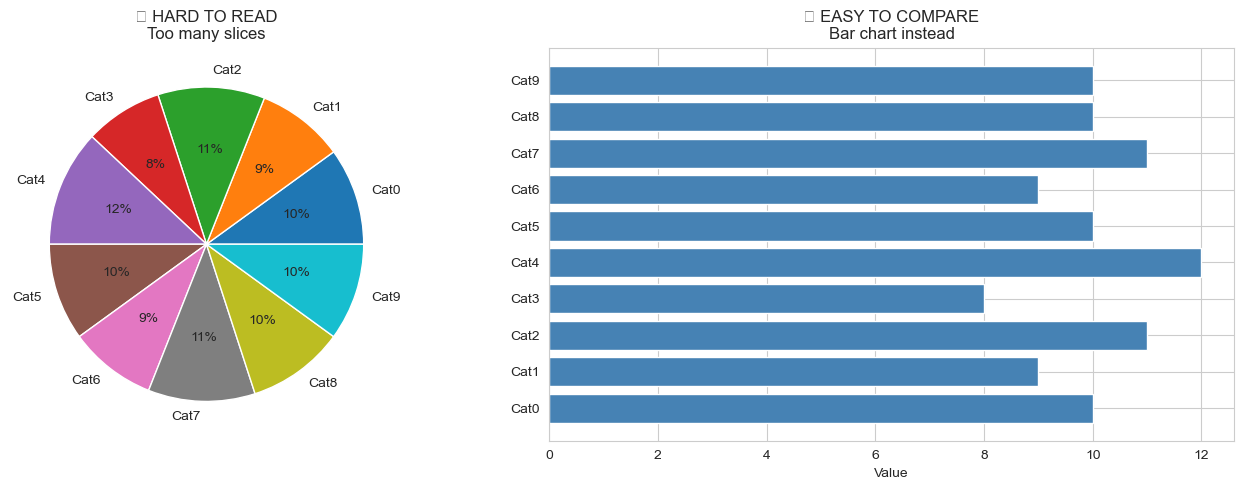

In [12]:
# BAD vs GOOD: Too many categories
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

many_categories = [f'Cat{i}' for i in range(10)]
many_values = [10, 9, 11, 8, 12, 10, 9, 11, 10, 10]

# BAD: Pie with many slices
axes[0].pie(many_values, labels=many_categories, autopct='%1.0f%%')
axes[0].set_title('❌ HARD TO READ\nToo many slices')

# GOOD: Horizontal bar chart
axes[1].barh(many_categories, many_values, color='steelblue')
axes[1].set_xlabel('Value')
axes[1].set_title('✓ EASY TO COMPARE\nBar chart instead')

plt.tight_layout()
plt.show()

### Mistake 3: 3D When 2D Would Work

/var/folders/pz/82_6wg3s3jngvml3zjpsjgdh0000gn/T/ipykernel_73874/2016929802.py:19: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/pz/82_6wg3s3jngvml3zjpsjgdh0000gn/T/ipykernel_73874/2016929802.py:19: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()


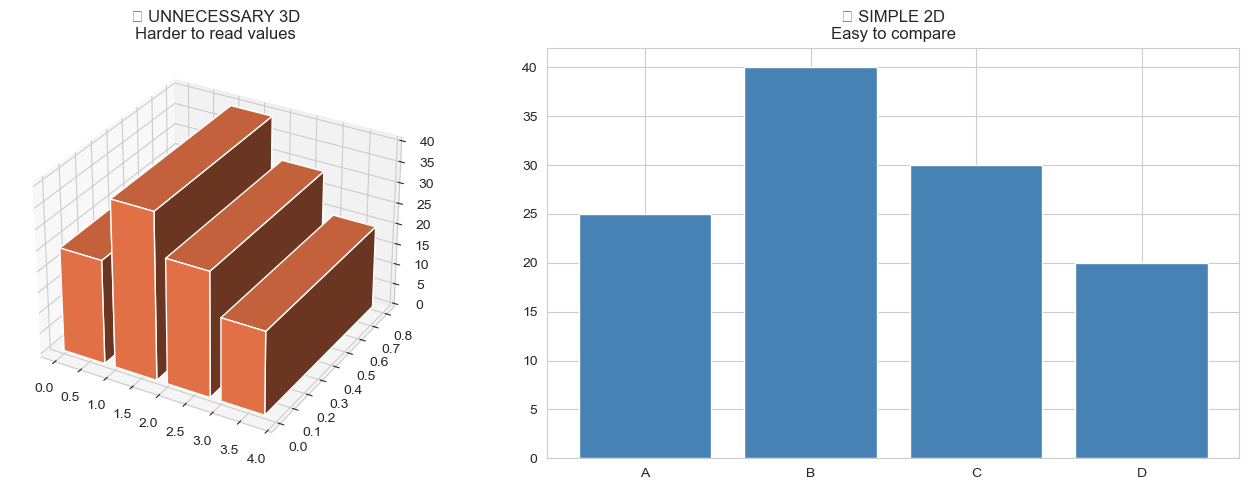

In [13]:
# BAD vs GOOD: Unnecessary 3D
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(14, 5))

categories = ['A', 'B', 'C', 'D']
values = [25, 40, 30, 20]

# BAD: 3D bar chart
ax1 = fig.add_subplot(121, projection='3d')
ax1.bar3d([0, 1, 2, 3], [0]*4, [0]*4, 0.8, 0.8, values, color='coral')
ax1.set_title('❌ UNNECESSARY 3D\nHarder to read values')

# GOOD: Simple 2D
ax2 = fig.add_subplot(122)
ax2.bar(categories, values, color='steelblue')
ax2.set_title('✓ SIMPLE 2D\nEasy to compare')

plt.tight_layout()
plt.show()

In [ ]:
# ═══ CHECKPOINT — "Visualization Dos and Donts" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['figure.figsize'] = (10, 6)
df = sns.load_dataset('tips')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig, ax = plt.subplots(figsize=(8, 6))
corr = df.select_dtypes(include=[np.number]).corr()
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
bimodal = np.concatenate([np.random.normal(-2, 0.5, 500), np.random.normal(2, 0.5, 500)])
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
n = 100
x = np.random.randn(n)
x_clusters = np.concatenate([np.random.randn(50) - 2, np.random.randn(50) + 2])
y_clusters = np.concatenate([np.random.randn(50) - 2, np.random.randn(50) + 2])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
values = [98, 99, 100, 101, 102]
categories = ['A', 'B', 'C', 'D', 'E']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
many_categories = [f'Cat{i}' for i in range(10)]
many_values = [10, 9, 11, 8, 12, 10, 9, 11, 10, 10]
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(14, 5))
categories = ['A', 'B', 'C', 'D']
values = [25, 40, 30, 20]
ax1 = fig.add_subplot(121, projection='3d')
ax2 = fig.add_subplot(122)

print("Checkpoint restored. Ready for: Visualization Dos and Donts")

### Visualization Do's and Don'ts

| ❌ DON'T | ✓ DO |
|----------|------|
| Truncate y-axis to exaggerate | Start y-axis at 0 for bar charts |
| Use pie charts with >5 slices | Use bar charts for many categories |
| Use 3D when 2D would work | Keep it simple |
| Use rainbow color schemes | Use colorblind-friendly palettes |
| Omit axis labels | Always label axes |
| Use misleading aspect ratios | Keep proportions honest |

---

## 6. Complete EDA Example

Let's walk through a complete EDA of the Tips dataset.

In [14]:
# Step 1: Load
tips = sns.load_dataset('tips')

print("="*60)
print("EXPLORATORY DATA ANALYSIS: Restaurant Tips")
print("="*60)

# Step 2: Inspect
print(f"\nDataset: {tips.shape[0]} rows, {tips.shape[1]} columns")
print(f"\nColumns: {list(tips.columns)}")
print(f"\nNumeric columns: {list(tips.select_dtypes(include=[np.number]).columns)}")
print(f"Categorical columns: {list(tips.select_dtypes(include=['category', 'object']).columns)}")

EXPLORATORY DATA ANALYSIS: Restaurant Tips

Dataset: 244 rows, 7 columns

Columns: ['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']

Numeric columns: ['total_bill', 'tip', 'size']
Categorical columns: ['sex', 'smoker', 'day', 'time']



UNIVARIATE ANALYSIS: One Variable at a Time


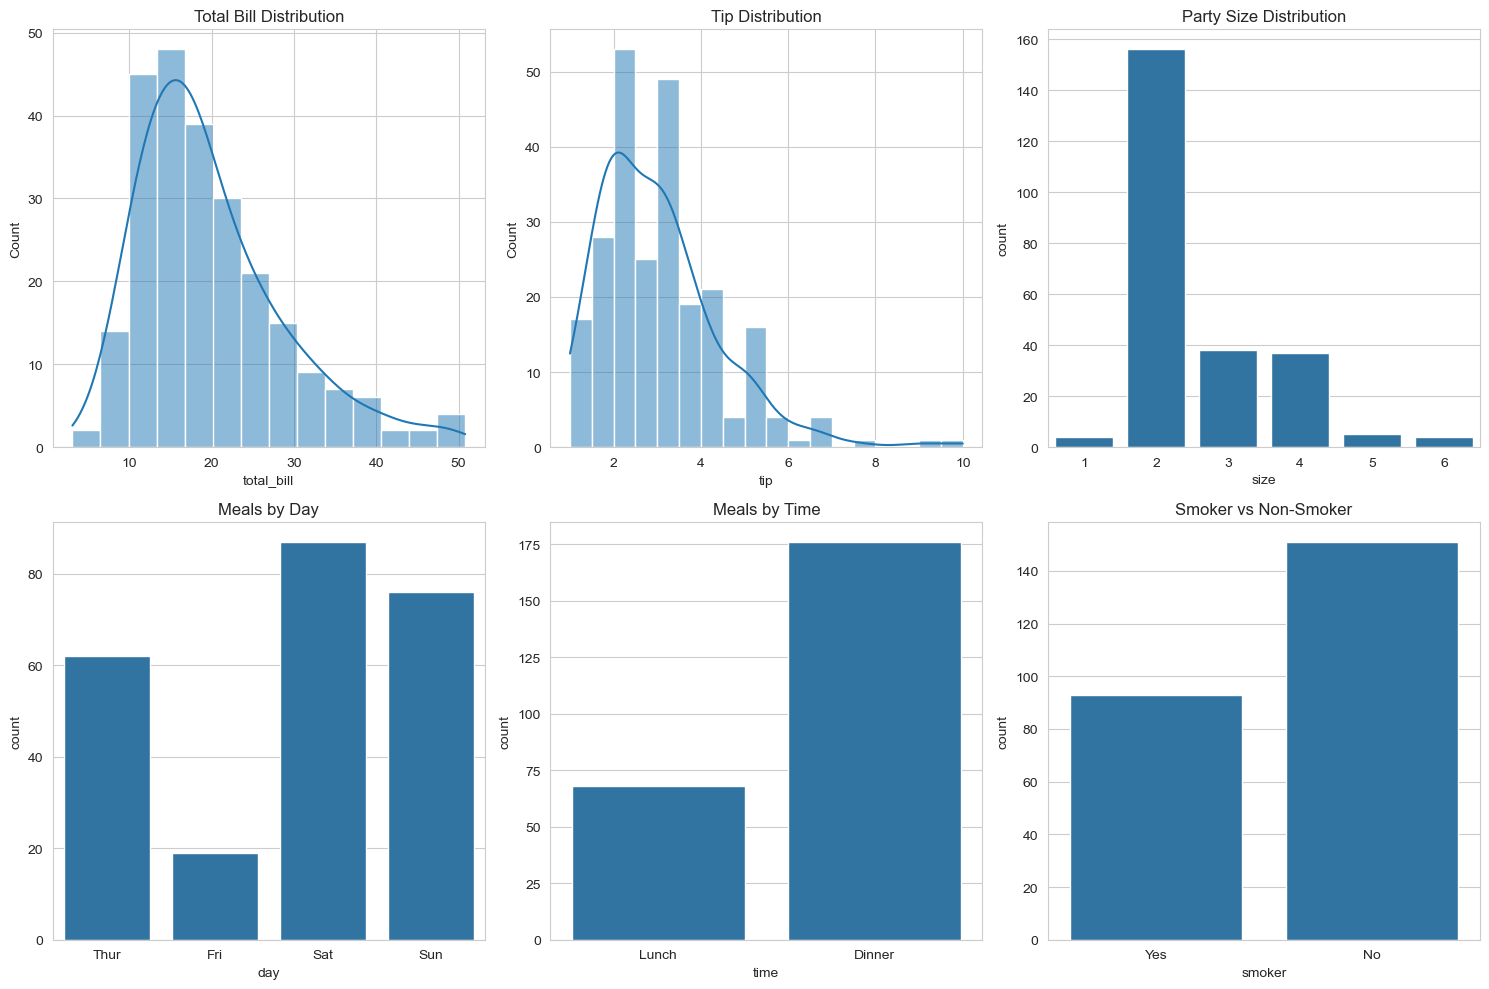

In [15]:
# Step 4: Explore - Univariate Analysis
print("\n" + "="*60)
print("UNIVARIATE ANALYSIS: One Variable at a Time")
print("="*60)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Numeric distributions
sns.histplot(tips['total_bill'], kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Total Bill Distribution')

sns.histplot(tips['tip'], kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Tip Distribution')

sns.countplot(data=tips, x='size', ax=axes[0, 2])
axes[0, 2].set_title('Party Size Distribution')

# Categorical distributions
sns.countplot(data=tips, x='day', ax=axes[1, 0])
axes[1, 0].set_title('Meals by Day')

sns.countplot(data=tips, x='time', ax=axes[1, 1])
axes[1, 1].set_title('Meals by Time')

sns.countplot(data=tips, x='smoker', ax=axes[1, 2])
axes[1, 2].set_title('Smoker vs Non-Smoker')

plt.tight_layout()
plt.show()


BIVARIATE ANALYSIS: Two Variables at a Time


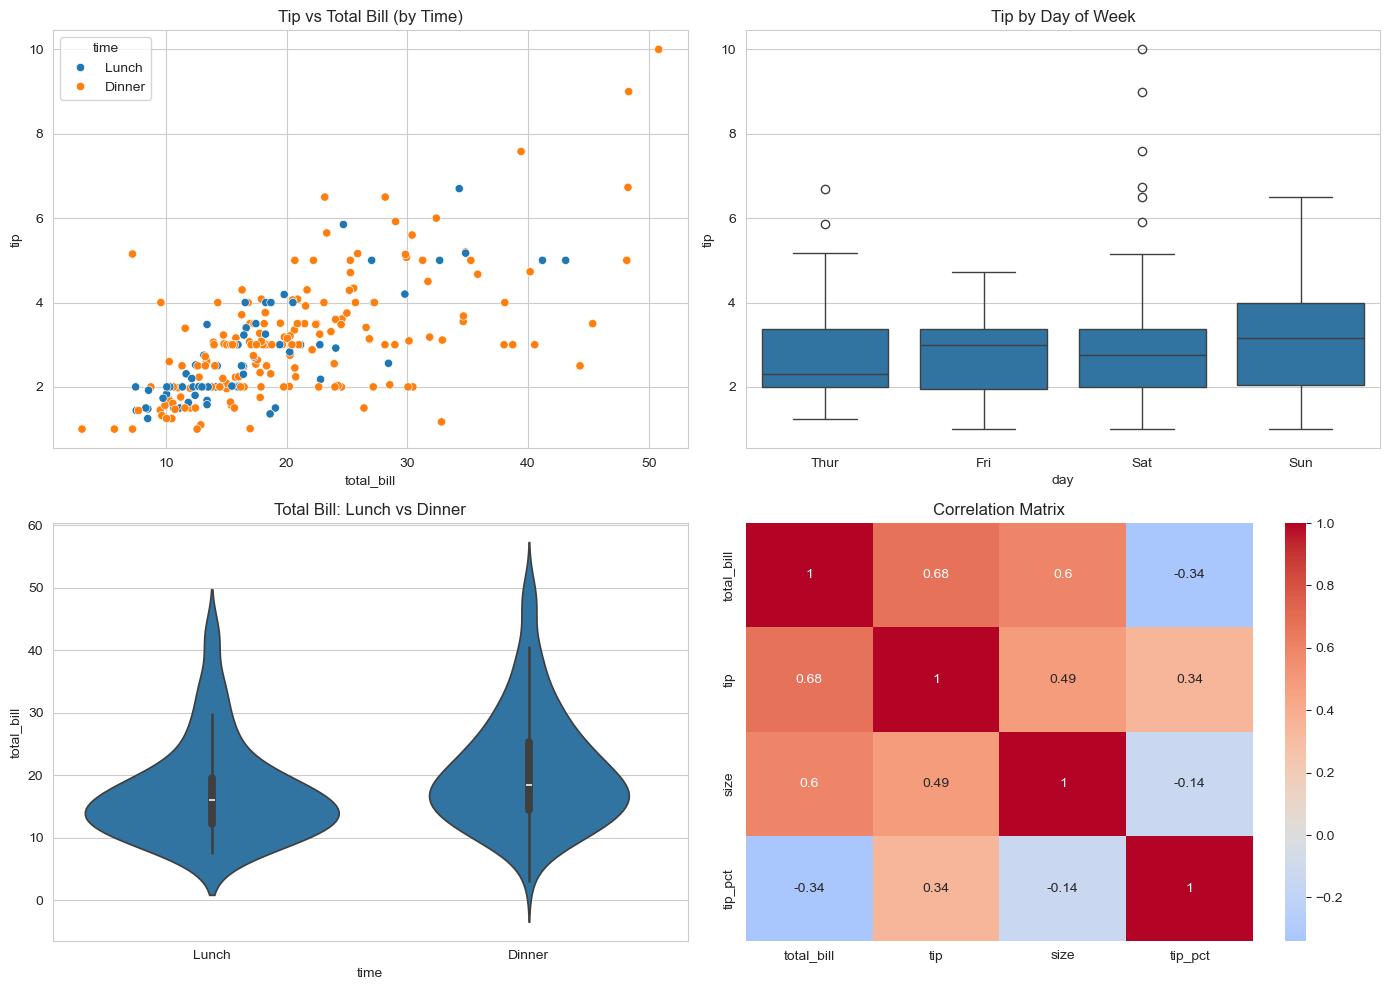

In [16]:
# Step 4: Explore - Bivariate Analysis
print("\n" + "="*60)
print("BIVARIATE ANALYSIS: Two Variables at a Time")
print("="*60)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Numeric vs Numeric
sns.scatterplot(data=tips, x='total_bill', y='tip', hue='time', ax=axes[0, 0])
axes[0, 0].set_title('Tip vs Total Bill (by Time)')

# Calculate tip percentage
tips['tip_pct'] = tips['tip'] / tips['total_bill'] * 100

# Categorical vs Numeric
sns.boxplot(data=tips, x='day', y='tip', ax=axes[0, 1])
axes[0, 1].set_title('Tip by Day of Week')

sns.violinplot(data=tips, x='time', y='total_bill', ax=axes[1, 0])
axes[1, 0].set_title('Total Bill: Lunch vs Dinner')

# Correlation heatmap
corr = tips.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, ax=axes[1, 1])
axes[1, 1].set_title('Correlation Matrix')

plt.tight_layout()
plt.show()


MULTIVARIATE ANALYSIS: Multiple Variables


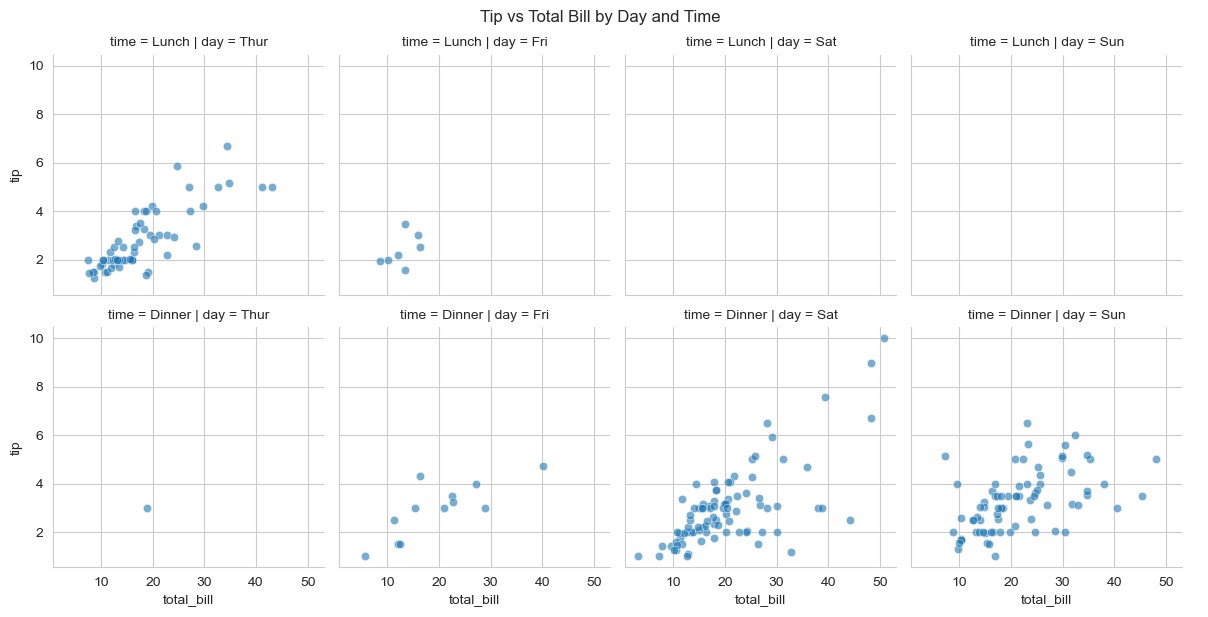

In [17]:
# Step 4: Explore - Multivariate Analysis
print("\n" + "="*60)
print("MULTIVARIATE ANALYSIS: Multiple Variables")
print("="*60)

# FacetGrid: Tip vs Bill, faceted by Day and Time
g = sns.FacetGrid(tips, col='day', row='time', height=3)
g.map(sns.scatterplot, 'total_bill', 'tip', alpha=0.6)
g.add_legend()
plt.suptitle('Tip vs Total Bill by Day and Time', y=1.02)
plt.show()

In [18]:
# Step 5: Summarize Key Findings
print("\n" + "="*60)
print("KEY FINDINGS SUMMARY")
print("="*60)

print("""
1. DISTRIBUTION:
   - Total bills: Right-skewed, most $10-30, some high outliers
   - Tips: Right-skewed, most $2-4
   - Party size: Most common is 2 people

2. TIME PATTERNS:
   - More dinner meals than lunch
   - Weekend (Sat/Sun) has more customers
   - Dinner bills higher than lunch

3. RELATIONSHIPS:
   - Strong positive correlation: Total bill vs Tip (r = 0.68)
   - Tip percentage fairly consistent across days
   - Larger parties have higher bills (expected)

4. OUTLIERS:
   - Some very high bills ($40-50)
   - A few exceptionally generous tips

5. NEXT STEPS:
   - Investigate the high-bill outliers
   - Build model to predict tip amount
   - Analyze tip percentage by server (if data available)
""")


KEY FINDINGS SUMMARY

1. DISTRIBUTION:
   - Total bills: Right-skewed, most $10-30, some high outliers
   - Tips: Right-skewed, most $2-4
   - Party size: Most common is 2 people

2. TIME PATTERNS:
   - More dinner meals than lunch
   - Weekend (Sat/Sun) has more customers
   - Dinner bills higher than lunch

3. RELATIONSHIPS:
   - Strong positive correlation: Total bill vs Tip (r = 0.68)
   - Tip percentage fairly consistent across days
   - Larger parties have higher bills (expected)

4. OUTLIERS:
   - Some very high bills ($40-50)
   - A few exceptionally generous tips

5. NEXT STEPS:
   - Investigate the high-bill outliers
   - Build model to predict tip amount
   - Analyze tip percentage by server (if data available)



---

## 7. Colorblind-Friendly Palettes

About 8% of men and 0.5% of women have some form of color blindness. Always consider accessibility!

In [ ]:
# TODO: draw a barplot of `day`, split by `time`
# Hint: plt.subplots, plt.suptitle, plt.tight_layout, plt.show, axes.ravel
# Name your result: palettes, palette

---

## Summary

In this notebook, you learned:

1. **EDA Workflow:** Load → Inspect → Clean → Explore → Summarize

2. **Chart Selection:**
   - 1 numeric → Histogram, Box
   - 2 numeric → Scatter, Regression
   - 1 numeric + 1 categorical → Box, Violin, Bar
   - Time series → Line plot
   - Correlations → Heatmap

3. **Interpretation:**
   - Distribution shapes (normal, skewed, bimodal)
   - Scatter patterns (positive, negative, clusters)
   - Box plot elements (IQR, median, outliers)
   - Correlation values (-1 to +1)

4. **Best Practices:**
   - Don't truncate y-axis
   - Avoid pie charts with many slices
   - Use 2D when possible
   - Use colorblind-friendly palettes

**This notebook is your reference guide - bookmark it!**

---

## Practice: Your Turn!

Apply the EDA workflow to a new dataset.

In [ ]:
# Load a new dataset
penguins = sns.load_dataset('penguins')

# Your EDA here:
# 1. Inspect the data
# 2. Check for missing values
# 3. Create univariate plots
# 4. Create bivariate plots
# 5. Summarize findings
